# 1. Config & Imports

In [1]:

from dataclasses import dataclass

@dataclass(frozen=True)
class Config:
    audio_root : str = "/kaggle/input/datasets/mishbhaul/indian-raga-dataset/RagaDataset/Hindustani/audio"
    features_csv : str = "mfcc_chroma_features.csv"

    # audio settings
    sr : int = 22050
    analysis_duration : float | None = None # considered full clip
    fmin_hz : float = 80.0
    fmax_hz : float = 800.0
    n_mfcc : int = 13              # standard MFCC coefficient count
    use_mfcc_delta : bool = True   # also include first-derivative (delta) MFCCs
    n_chroma : int = 12            # 12 = one bin per semitone
    align_chroma_to_tonic : bool = True  # circularly shift chroma so tonic bin -> index 0

    random_seed : int = 42
    AUDIO_EXTENSIONS = (".wav", ".mp3", ".flac", ".m4a")
cfg = Config()


In [2]:

import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("NUMBA_NUM_THREADS", "1")

import re
import warnings

import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from joblib import Parallel, delayed

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
np.random.seed(cfg.random_seed)


### Helper functions

In [3]:

# Raga IDs for 300 Hindustani Classical Music clips (30 ragas x 10 songs)
ID_TO_RAGA = {
    'f7fddfc0-8c1d-4dd2-90d5-5d51a99d61f8 2': 'Rāgēśrī',
    'f6432fec-e9c2-4b09-9e73-c46086cbd8ea': 'Ahira bhairav',
    '290674e0-d94c-41c1-ad99-f65fa22a1447': 'Madhuvanti',
    '0b3bbf97-0ec3-41da-add4-722d87329ec3': 'Madhukauns',
    'a9ee554f-f146-43e9-b2d0-9bb31fd4b57d': 'Kēdār',
    'd9c603fa-875f-4b84-b851-c6a345427898': 'Ābhōgī',
    '1e7de02f-e77f-405a-a033-f31117aaf955': 'Bhairav',
    '3eb7ba30-4b94-432e-9618-875ee57e01ab': 'Mārvā',
    '46997b02-f09c-4969-8138-4e1861f61967': 'Śrī',
    '54c4214c-05b9-4acc-8f77-6d5786e43a2e': 'Mārūbihāg',
    'a99e07d5-20a0-467b-8dcd-aa5a095177fd': 'Lalit',
    '62b79291-73b0-4c77-a353-0f8bc6ed8362': 'Dēś',
    '118401e7-8de8-4d81-9d8e-8070889e3fa8': 'Darbāri',
    '7591faad-e68a-4550-b675-8082842c6056': 'Bāgēśrī',
    '93c73081-bdf8-4eca-b325-d736b71e9b4b': 'Khamāj',
    'ba3242d0-8d40-4d93-865e-d2e2497ea2a8': 'Gauḍ malhār',
    'ecd04ceb-b46c-47fc-9045-84ac9160e527': 'Basant',
    '6f13484e-6fdd-402d-baf3-3835835454d0': 'Tōḍī',
    'fa28470c-d413-44c7-94da-181f530cbfdd': 'Puriyā dhanaśrī',
    'f7fddfc0-8c1d-4dd2-90d5-5d51a99d61f8': 'Rāgēśrī',
    '40dbe1db-858f-4366-bef8-9076eb67340d': 'Śuddh sāraṅg',
    '1b05a564-059f-445b-b325-cf26318367e3': 'Miyān malhār',
    'b143adaa-f1a6-4de4-8985-a5bd35e96279': 'Bairāgi',
    '64e5fb9e-5569-4e80-8e6c-f543af9469c7': 'Mālkauns',
    '2ed9379f-14c9-49af-8e4d-f9b63e96801f': 'Alahaiyā bilāval',
    'e771a74d-545d-41d5-816b-43403a818b0c': 'Bhūp',
    '063ea5a0-23b1-4bb5-8537-3d924fe8ebb3': 'Jōg',
    'a7d98897-e2fe-4d75-b9dc-e5b4dc88e1c6': 'Bihāg',
    '48b37bed-e847-4882-8a01-5c721e07f07d': 'Yaman kalyāṇ',
    '595de771-fcc2-414c-9df6-ae4ffd898549': 'Hamsadhvāni',
    'dd59147d-8775-44ff-a36b-0d9f15b31319': 'Bilāsakhānī tōḍī',
}

print(f"Loaded {len(ID_TO_RAGA)} raga id mappings "
      f"({len(set(ID_TO_RAGA.values()))} unique raga labels)")


def clean_uuid(raw_name: str) -> str:
    '''Normalize a folder name to its canonical uuid string.'''
    name = raw_name.strip()
    name = re.sub(r"\s*\(\d+\)$", "", name)   # trailing " (1)", " (2)"
    name = re.sub(r"\s+\d+$", "", name)       # trailing " 2", " 3"
    return name.lower()


def build_normalized_lookup(id_to_raga: dict) -> dict:
    '''Collapse duplicate-suffixed uuid keys into one clean lookup table.'''
    return {clean_uuid(k): v for k, v in id_to_raga.items()}


def find_audio_files_with_labels(root_dir: str, id_to_raga: dict) -> list[tuple[str, str, str]]:
    '''Walk `root_dir` and return (filepath, raga_label, artist) for every
    audio file whose parent uuid folder is present in `id_to_raga`.
    '''
    lookup = build_normalized_lookup(id_to_raga)
    items = []

    for uuid_folder in sorted(os.listdir(root_dir)):
        uuid_path = os.path.join(root_dir, uuid_folder)
        if not os.path.isdir(uuid_path):
            continue

        raga_label = lookup.get(clean_uuid(uuid_folder))
        if raga_label is None:
            print(f"WARNING: no raga mapping for uuid folder '{uuid_folder}', skipping")
            continue

        for dirpath, _, filenames in os.walk(uuid_path):
            rel_path = os.path.relpath(dirpath, uuid_path)
            artist = rel_path.split(os.sep)[0] if rel_path != "." else "unknown"

            for fname in filenames:
                if fname.lower().endswith(cfg.AUDIO_EXTENSIONS):
                    items.append((os.path.join(dirpath, fname), raga_label, artist))

    return items


Loaded 31 raga id mappings (30 unique raga labels)



# 2. Feature Extraction

### 2.1 Tonic estimation

Used here only to **align chroma to the tonic** (Section 2.3) — MFCCs
don't need it, since timbre isn't pitch-relative.


In [4]:

# "Cents" is just a unit for measuring musical pitch on a logarithmic scale
# 1200 cents = exactly 1 octave --> 100 cents = 1 semitone (12 semitones in an octave)
def estimate_tonic(audio : np.ndarray, sr : int, low_freq : float = cfg.fmin_hz, high_freq : float = cfg.fmax_hz):
    pitch_track, is_voiced, _ = librosa.pyin(
        audio, fmin=low_freq, fmax=high_freq, sr=sr, frame_length=2048
    )
    # keep only the pitch estimates where a clear pitch was actually detected
    if is_voiced is not None:
        clean_pitches = pitch_track[is_voiced]
    else:
        clean_pitches = pitch_track[~np.isnan(pitch_track)]
    clean_pitches = clean_pitches[~np.isnan(clean_pitches)]

    if len(clean_pitches) == 0:
        return 220.0  # no pitch detected in this clip, just return a default

    # convert to cents
    cents = 1200*np.log2(clean_pitches / low_freq)
    cents_in_one_octave = np.mod(cents, 1200)
    counts, bin_edges = np.histogram(cents_in_one_octave, bins=120, range=(0,1200))
    tallest_bin_position = bin_edges[np.argmax(counts)]

    # convert that cents value back into a frequency in Hz
    tonic_hz = low_freq * (2 ** (tallest_bin_position / 1200))
    return float(tonic_hz)


def tonic_to_chroma_bin(tonic_hz: float, n_chroma: int = cfg.n_chroma) -> int:
    '''Map a tonic frequency to the nearest chroma bin index (0 = C by librosa convention).'''
    semitones_from_c = 12 * np.log2(tonic_hz / 261.63)
    return int(round(semitones_from_c)) % n_chroma



### 2.2 MFCC extraction

Captures the *timbral* texture of the clip (spectral envelope shape).
We time-pool (mean + std across frames) each coefficient into a fixed-
length vector, plus optional delta (first-derivative) coefficients to
capture how the timbre changes over time.


In [5]:

def extract_mfcc_features(y: np.ndarray, sr: int, n_mfcc: int = cfg.n_mfcc,
                           use_delta: bool = cfg.use_mfcc_delta) -> dict:
    '''Compute MFCCs (+ deltas), time-pooled to mean/std per coefficient.'''
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)

    feat = {}
    for i in range(n_mfcc):
        feat[f"mfcc_{i}_mean"] = float(np.mean(mfcc[i]))
        feat[f"mfcc_{i}_std"] = float(np.std(mfcc[i]))

    if use_delta:
        delta = librosa.feature.delta(mfcc)
        for i in range(n_mfcc):
            feat[f"mfcc_delta_{i}_mean"] = float(np.mean(delta[i]))
            feat[f"mfcc_delta_{i}_std"] = float(np.std(delta[i]))

    return feat



### 2.3 Chroma extraction

Captures *pitch-class* energy — the off-the-shelf, spectrogram-based
analogue of a PCD, computed directly via CQT rather than from onset-
segmented notes. Since Hindustani "Sa" is a movable tonic but chroma
bins are absolute pitch (C, C#, D, ...), we optionally roll the chroma
vector so the tonic bin lands at index 0, using the tonic estimated in
2.1 — this makes clips in different keys comparable.


In [6]:

def extract_chroma_features(y: np.ndarray, sr: int, tonic_hz: float | None = None,
                             n_chroma: int = cfg.n_chroma,
                             align_to_tonic: bool = cfg.align_chroma_to_tonic) -> dict:
    '''Compute chroma-CQT, optionally tonic-aligned, time-pooled to mean/std per bin.'''
    chroma = librosa.feature.chroma_cqt(y=y, sr=sr, n_chroma=n_chroma)

    if align_to_tonic and tonic_hz is not None:
        shift = tonic_to_chroma_bin(tonic_hz, n_chroma)
        chroma = np.roll(chroma, -shift, axis=0)  # tonic bin -> index 0

    feat = {}
    for i in range(n_chroma):
        feat[f"chroma_{i}_mean"] = float(np.mean(chroma[i]))
        feat[f"chroma_{i}_std"] = float(np.std(chroma[i]))

    return feat


# 3. Build Feature Table

In [7]:

def process_file(filepath: str, raga_label: str, artist: str,
                  sr_target: int = cfg.sr,
                  duration: float | None = cfg.analysis_duration) -> dict:
    '''Load one clip and compute its MFCC + chroma feature row.'''
    y, sr = librosa.load(filepath, sr=sr_target, duration=duration, mono=True)
    y, _ = librosa.effects.trim(y, top_db=30)

    tonic_hz = estimate_tonic(y, sr) if cfg.align_chroma_to_tonic else None
    mfcc_feat = extract_mfcc_features(y, sr)
    chroma_feat = extract_chroma_features(y, sr, tonic_hz=tonic_hz)

    row = {"filepath": filepath, "artist": artist, "raga": raga_label,
           "tonic_hz": tonic_hz if tonic_hz is not None else np.nan}
    row.update(mfcc_feat)
    row.update(chroma_feat)
    return row


def _safe_process_file(filepath: str, raga_label: str, artist: str) -> dict | None:
    '''Wrap process_file so one bad/corrupt clip returns None instead of
    raising inside a worker.'''
    try:
        return process_file(filepath, raga_label, artist)
    except Exception as e:
        print(f"FAILED  {filepath}: {e}")
        return None


def safe_filename(name: str) -> str:
    '''Turn a raga label into a filesystem-safe filename.'''
    return re.sub(r"[^\w\-]+", "_", name.strip()).strip("_").lower()


def build_feature_table_for_raga(raga_name: str, root: str, id_to_raga: dict,
                                  out_dir: str = "raga_features",
                                  force: bool = False,
                                  n_jobs: int = 4) -> pd.DataFrame:
    '''Extract MFCC + chroma features for a single raga only, in parallel
    across n_jobs CPU cores, caching the result to its own CSV.'''
    os.makedirs(out_dir, exist_ok=True)
    raga_csv = os.path.join(out_dir, f"{safe_filename(raga_name)}.csv")

    if os.path.exists(raga_csv) and not force:
        print(f"Loading cached features for '{raga_name}' from {raga_csv}")
        return pd.read_csv(raga_csv)

    all_files = find_audio_files_with_labels(root, id_to_raga)
    raga_files = [(fp, label, artist) for fp, label, artist in all_files if label == raga_name]
    if not raga_files:
        raise ValueError(f"No audio files found for raga '{raga_name}'")

    print(f"Found {len(raga_files)} audio files for raga '{raga_name}' (n_jobs={n_jobs})")

    results = Parallel(n_jobs=n_jobs, backend="loky")(
        delayed(_safe_process_file)(filepath, raga_label, artist)
        for filepath, raga_label, artist in tqdm(raga_files, desc=f"Extracting: {raga_name}")
    )

    rows = [r for r in results if r is not None]
    if len(rows) < len(raga_files):
        print(f"WARNING: {len(raga_files) - len(rows)} file(s) failed for '{raga_name}'")

    df = pd.DataFrame(rows)
    df.to_csv(raga_csv, index=False)
    print(f"Saved {len(df)} rows to {raga_csv}")
    return df


def combine_all_raga_features(out_dir: str = "raga_features",
                               out_csv: str = cfg.features_csv) -> pd.DataFrame:
    '''Once you've run build_feature_table_for_raga on all ragas you want,
    stitch their per-raga CSVs together into one combined feature table.'''
    csv_files = sorted(f for f in os.listdir(out_dir) if f.endswith(".csv"))
    if not csv_files:
        raise FileNotFoundError(f"No per-raga CSVs found in {out_dir}")

    dfs = [pd.read_csv(os.path.join(out_dir, f)) for f in csv_files]
    combined = pd.concat(dfs, ignore_index=True)
    combined.to_csv(out_csv, index=False)

    n_ragas = combined["raga"].nunique() if len(combined) else 0
    print(f"Combined {len(csv_files)} raga CSV(s) -> {len(combined)} rows -> {out_csv}")
    print(f"Ragas represented: {n_ragas}")
    return combined


In [8]:

# Set this to whichever raga you want to extract features for right now.
# Re-run this cell with a different name to process the next raga.
# Already-processed ragas load instantly from their cached CSV.
raga_to_process = "Kēdār"

raga_df = build_feature_table_for_raga(raga_to_process, cfg.audio_root, ID_TO_RAGA, n_jobs=4)
raga_df.head()


Found 10 audio files for raga 'Kēdār' (n_jobs=4)


Extracting: Kēdār:   0%|          | 0/10 [00:00<?, ?it/s]

Saved 10 rows to raga_features/kēdār.csv


,filepath,artist,raga,tonic_hz,mfcc_0_mean,mfcc_0_std,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,...,chroma_7_mean,chroma_7_std,chroma_8_mean,chroma_8_std,chroma_9_mean,chroma_9_std,chroma_10_mean,chroma_10_std,chroma_11_mean,chroma_11_std
0,/kaggle/input/datasets/mishbhaul/indian-raga-d...,Abdul_Rashid_Khan,Kēdār,91.366587,-180.792740,54.333599,87.583641,20.317526,-32.628315,14.243167,...,0.503472,0.295712,0.297981,0.222969,0.384357,0.264110,0.298897,0.224043,0.411244,0.251460
1,/kaggle/input/datasets/mishbhaul/indian-raga-d...,Abdul_Rashid_Khan,Kēdār,137.688230,-158.881363,51.368565,93.322144,20.753843,-29.126740,12.785304,...,0.630005,0.283378,0.386394,0.224104,0.410994,0.266002,0.374999,0.236902,0.415221,0.259676
2,/kaggle/input/datasets/mishbhaul/indian-raga-d...,Abdul_Rashid_Khan,Kēdār,137.688230,-142.028931,49.594254,93.003708,21.326174,-31.047720,13.601420,...,0.634170,0.270907,0.391550,0.228059,0.426739,0.256044,0.412739,0.245712,0.460511,0.274619
3,/kaggle/input/datasets/mishbhaul/indian-raga-d...,Abdul_Rashid_Khan,Kēdār,137.688230,-149.376694,48.347744,84.074776,21.790020,-30.391935,13.046776,...,0.597532,0.268480,0.372241,0.243733,0.399339,0.266121,0.356649,0.225531,0.419198,0.259404
4,/kaggle/input/datasets/mishbhaul/indian-raga-d...,Abdul_Rashid_Khan,Kēdār,135.322829,-135.651154,47.866283,88.539124,20.873920,-30.684172,13.758303,...,0.634834,0.270006,0.406047,0.236022,0.410155,0.255576,0.354253,0.217306,0.436959,0.256025



### Combine per-raga results

Run once you've extracted features for all the ragas you need.


In [9]:

# Once you've processed all the ragas you care about above (re-running
# cell above with a new `raga_to_process` each time), run this to build
# the single combined table the EDA section below expects.
if os.path.exists(cfg.features_csv):
    print(f"Loading cached combined features from {cfg.features_csv}")
    features_df = pd.read_csv(cfg.features_csv)
else:
    features_df = combine_all_raga_features()

features_df.head()


Combined 1 raga CSV(s) -> 10 rows -> mfcc_chroma_features.csv
Ragas represented: 1


,filepath,artist,raga,tonic_hz,mfcc_0_mean,mfcc_0_std,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,...,chroma_7_mean,chroma_7_std,chroma_8_mean,chroma_8_std,chroma_9_mean,chroma_9_std,chroma_10_mean,chroma_10_std,chroma_11_mean,chroma_11_std
0,/kaggle/input/datasets/mishbhaul/indian-raga-d...,Abdul_Rashid_Khan,Kēdār,91.366587,-180.792740,54.333599,87.583641,20.317526,-32.628315,14.243167,...,0.503472,0.295712,0.297981,0.222969,0.384357,0.264110,0.298897,0.224043,0.411244,0.251460
1,/kaggle/input/datasets/mishbhaul/indian-raga-d...,Abdul_Rashid_Khan,Kēdār,137.688230,-158.881363,51.368565,93.322144,20.753843,-29.126740,12.785304,...,0.630005,0.283378,0.386394,0.224104,0.410994,0.266002,0.374999,0.236902,0.415221,0.259676
2,/kaggle/input/datasets/mishbhaul/indian-raga-d...,Abdul_Rashid_Khan,Kēdār,137.688230,-142.028931,49.594254,93.003708,21.326174,-31.047720,13.601420,...,0.634170,0.270907,0.391550,0.228059,0.426739,0.256044,0.412739,0.245712,0.460511,0.274619
3,/kaggle/input/datasets/mishbhaul/indian-raga-d...,Abdul_Rashid_Khan,Kēdār,137.688230,-149.376694,48.347744,84.074776,21.790020,-30.391935,13.046776,...,0.597532,0.268480,0.372241,0.243733,0.399339,0.266121,0.356649,0.225531,0.419198,0.259404
4,/kaggle/input/datasets/mishbhaul/indian-raga-d...,Abdul_Rashid_Khan,Kēdār,135.322829,-135.651154,47.866283,88.539124,20.873920,-30.684172,13.758303,...,0.634834,0.270006,0.406047,0.236022,0.410155,0.255576,0.354253,0.217306,0.436959,0.256025


# 4. EDA

Total clips: 10
Unique ragas: 1
Unique artists: 6


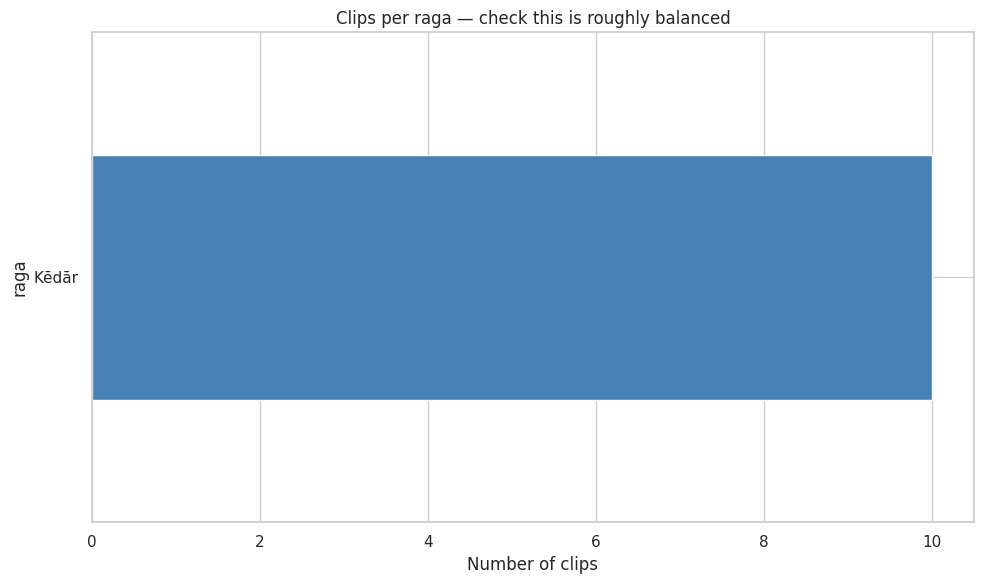

In [10]:

print(f"Total clips: {len(features_df)}")
print(f"Unique ragas: {features_df['raga'].nunique()}")
print(f"Unique artists: {features_df['artist'].nunique()}")

fig, ax = plt.subplots(figsize=(10, 6))
features_df["raga"].value_counts().sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_xlabel("Number of clips")
ax.set_title("Clips per raga — check this is roughly balanced")
plt.tight_layout()
plt.show()


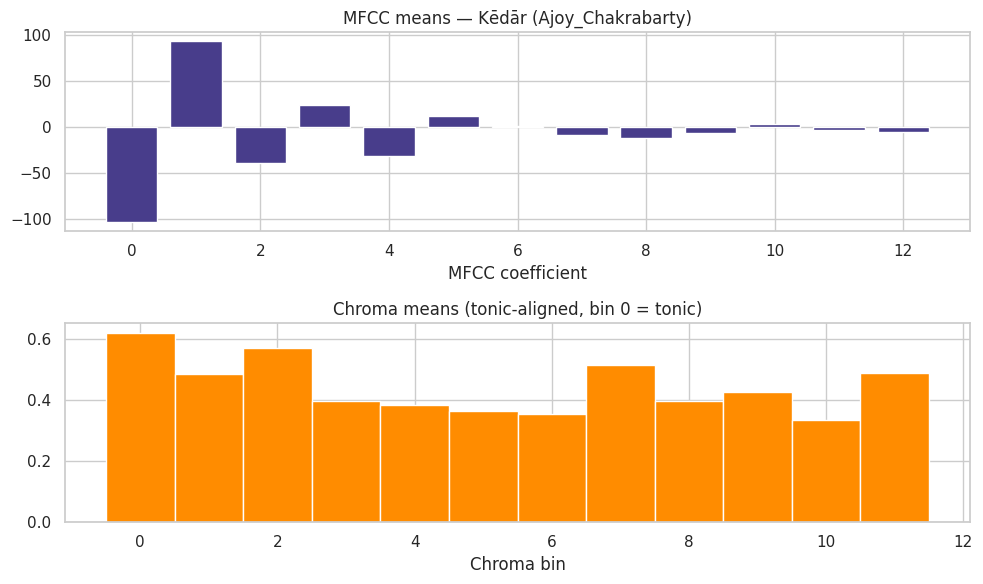

In [11]:

mfcc_cols = [c for c in features_df.columns if c.startswith("mfcc_")]
chroma_cols = [c for c in features_df.columns if c.startswith("chroma_")]

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
example = features_df.sample(1, random_state=cfg.random_seed).iloc[0]

mfcc_mean_cols = [c for c in mfcc_cols if c.endswith("_mean") and "delta" not in c]
axes[0].bar(range(len(mfcc_mean_cols)), example[mfcc_mean_cols].values, color="darkslateblue")
axes[0].set_title(f"MFCC means — {example['raga']} ({example['artist']})")
axes[0].set_xlabel("MFCC coefficient")

chroma_mean_cols = [c for c in chroma_cols if c.endswith("_mean")]
axes[1].bar(range(len(chroma_mean_cols)), example[chroma_mean_cols].values, color="darkorange", width=1.0)
axes[1].set_title("Chroma means (tonic-aligned, bin 0 = tonic)" if cfg.align_chroma_to_tonic
                   else "Chroma means (absolute pitch, bin 0 = C)")
axes[1].set_xlabel("Chroma bin")

plt.tight_layout()
plt.show()
